# Megaline — análise de receita dos planos Surf e Ultimate

Estudo do comportamento de uso e da receita gerada por dois planos pré-pagoss de telecomunicações. A análise combina preparação de dados, regras de cobrança, comportamento mensal dos usuários e testes de hipótese.

**Ferramentas:** Python, pandas, numpy, matplotlib, seaborn e scipy.


## Contexto e objetivo

A partir de uma amostra de 500 clientes, o objetivo é comparar os planos Surf e Ultimate, entender como chamadas, mensagens e consumo de internet se relacionam com a receita e produzir recomendações comerciais baseadas nos dados.


## Configuração


In [1]:
# Carregando todas as bibliotecas
import pandas as pd
from scipy import stats as st
import math as mt
from matplotlib import pyplot as plt
import numpy as np
import seaborn as sns


## Carregamento dos dados


In [2]:
# Carregamento dos arquivos em DataFrames
df_users = pd.read_csv('data/megaline_users.csv')
df_calls = pd.read_csv('data/megaline_calls.csv')
df_messages  = pd.read_csv('data/megaline_messages.csv')
df_internet  = pd.read_csv('data/megaline_internet.csv')
df_plans  = pd.read_csv('data/megaline_plans.csv')


## Preparação dos dados


## Planos

In [3]:
# Imprima informações gerais/resumo sobre o DataFrame dos planos
df_plans.info()
print()
df_plans.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes



,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
count,2.000000,2.000000,2.000000,2.000000,2.00000,2.000000,2.000000
mean,525.000000,23040.000000,1750.000000,45.000000,8.50000,0.020000,0.020000
std,671.751442,10861.160159,1767.766953,35.355339,2.12132,0.014142,0.014142
min,50.000000,15360.000000,500.000000,20.000000,7.00000,0.010000,0.010000
25%,287.500000,19200.000000,1125.000000,32.500000,7.75000,0.015000,0.015000
50%,525.000000,23040.000000,1750.000000,45.000000,8.50000,0.020000,0.020000
75%,762.500000,26880.000000,2375.000000,57.500000,9.25000,0.025000,0.025000
max,1000.000000,30720.000000,3000.000000,70.000000,10.00000,0.030000,0.030000


In [4]:
df_plans.head()

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


**Obs sobre o DataFrame**

O DataFrame sobre os planos não apresenta problemas de dados ausentes ou tipos inadequados, e os valores estão consistentes com as condições dos planos. Por razões de clareza, modificarei os nomes das colunas usd_per_gb	usd_per_message	usd_per_minut para usd_per_extra_gb, usd_per_extra_message, usd_per_extra_minut.

## Limpeza e padronização


In [5]:
# Modificando nomes das colunas para fins de clareza

novas_colunas = {
    'usd_per_gb': 'usd_per_extra_gb',
    'usd_per_message': 'usd_per_extra_message',
    'usd_per_minute': 'usd_per_extra_minut'
}

df_plans = df_plans.rename(columns = novas_colunas)
display(df_plans)

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_extra_gb,usd_per_extra_message,usd_per_extra_minut,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


## Preparação de variáveis


[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [6]:
# Não é o caso de enriquecer dados nesta tabela, até o momento.

## Usuários

In [7]:
# Imprima informações gerais/resumo sobre o DataFrame dos usuários

df_users.info()
print()
df_users.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB



,user_id,age
count,500.000000,500.000000
mean,1249.500000,45.486000
std,144.481833,16.972269
min,1000.000000,18.000000
25%,1124.750000,30.000000
50%,1249.500000,46.000000
75%,1374.250000,61.000000
max,1499.000000,75.000000


In [8]:
# Imprima uma amostra de dados dos usuários

display(df_users.head())
print()
display(df_users.sample(15, random_state = 29))
print()
display(df_users.duplicated().sum())


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaN
1,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaN
2,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,surf,NaN
3,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,surf,NaN
4,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,surf,NaN


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
165,1165,Nigel,Huber,20,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD MSA",2018-10-27,surf,NaN
272,1272,Ernest,Mercado,23,"Minneapolis-St. Paul-Bloomington, MN-WI MSA",2018-08-04,surf,NaN
191,1191,Zack,Waters,75,"St. Louis, MO-IL MSA",2018-01-21,ultimate,2018-11-30
405,1405,Shella,Hunter,34,"Indianapolis-Carmel-Anderson, IN MSA",2018-06-22,ultimate,NaN
29,1029,Franklyn,Henson,59,"Tampa-St. Petersburg-Clearwater, FL MSA",2018-01-05,surf,NaN
452,1452,Miguel,Sparks,32,"Tucson, AZ MSA",2018-12-29,surf,NaN
357,1357,Ria,Beach,61,"Baton Rouge, LA MSA",2018-05-30,surf,NaN
448,1448,Elayne,Foley,33,"Urban Honolulu, HI MSA",2018-10-17,surf,NaN
293,1293,Lanny,Nolan,23,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD MSA",2018-08-13,surf,NaN
168,1168,Shay,Weaver,58,"Milwaukee-Waukesha, WI MSA",2018-12-13,surf,NaN


0

**Obs sobre o DataFrame**

As colunas reg_date e churn_date registram datas, mas seu tipo está como object. Melhor modificar para datetime.

Há 34 pessoas, dentre as 500, que já deixaram de ser clientes. Não presumo agora que essas linhas devam ser descartadas, mas talvez seja necessário no futuro. Pode ser interessante sort_values() para visualizar quando isso começou e o intervalo de tempo pelo qual se estendem essas desistências, o que ajudaria em um possível diagnóstico de motivações.

Não há valores duplicados. Há valores ausentes apenas em churn_date.



### Limpeza e padronização


[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [9]:
# Alterando tipo de dado object para datatime na coluna reg_date

teste = pd.to_datetime(df_users['reg_date'], format = '%Y-%m-%d')
teste.head()

# Fiz o teste antes para não alterar o conjunto original erroneamente. Agora, reatribuindo:
df_users['reg_date'] = pd.to_datetime(df_users['reg_date'], format = '%Y-%m-%d')
display(df_users['reg_date'].head())

0   2018-12-24
1   2018-08-13
2   2018-10-21
3   2018-01-28
4   2018-05-23
Name: reg_date, dtype: datetime64[ns]

In [10]:
# Alterando tipo de dado object para datatime na coluna churn_date

teste = pd.to_datetime(df_users['churn_date'], format = '%Y-%m-%d')
teste.sample(30, random_state = 29)

#reatribuindo
df_users['churn_date'] = pd.to_datetime(df_users['churn_date'], format = '%Y-%m-%d')
display(df_users['reg_date'].head())
display(df_users.info())

#valores nulos permanecem iguais

0   2018-12-24
1   2018-08-13
2   2018-10-21
3   2018-01-28
4   2018-05-23
Name: reg_date, dtype: datetime64[ns]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    object        
 2   last_name   500 non-null    object        
 3   age         500 non-null    int64         
 4   city        500 non-null    object        
 5   reg_date    500 non-null    datetime64[ns]
 6   plan        500 non-null    object        
 7   churn_date  34 non-null     datetime64[ns]
dtypes: datetime64[ns](2), int64(2), object(4)
memory usage: 31.4+ KB


None

### Preparação de variáveis


[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [11]:
# verificando se há um período temporal especifico em que clientes deixaram os planos

df_users_sortby_churn_date = df_users['churn_date'].sort_values()
display(df_users_sortby_churn_date.head(35))
print()
display(df_users['reg_date'].sort_values().head())
print()
display(df_users['reg_date'].sort_values().tail())


246   2018-07-31
363   2018-08-16
441   2018-08-19
414   2018-09-01
22    2018-09-07
466   2018-09-17
491   2018-09-18
315   2018-10-03
50    2018-10-07
220   2018-10-13
358   2018-10-22
84    2018-11-11
106   2018-11-14
281   2018-11-14
12    2018-11-16
467   2018-11-18
416   2018-11-21
67    2018-11-24
172   2018-11-29
191   2018-11-30
451   2018-12-10
94    2018-12-12
269   2018-12-15
6     2018-12-18
296   2018-12-18
83    2018-12-18
300   2018-12-19
298   2018-12-19
180   2018-12-22
402   2018-12-26
129   2018-12-27
40    2018-12-30
54    2018-12-31
186   2018-12-31
0            NaT
Name: churn_date, dtype: datetime64[ns]

482   2018-01-01
214   2018-01-01
251   2018-01-01
301   2018-01-04
439   2018-01-04
Name: reg_date, dtype: datetime64[ns]

452   2018-12-29
108   2018-12-30
323   2018-12-30
307   2018-12-31
473   2018-12-31
Name: reg_date, dtype: datetime64[ns]

Nos códigos acima, procurei conferir o período temporal de que se tratam os dados, para verificar se haveria um intervalo de tempo específico em que clientes começaram a deixar o plano. O período é o ano de 2018 todo, e as saídas estão totalmente concentradas entre fim de julho a fim de dezembro. Há algum motivo específico para tanto, aparentemente. Pode ser permanência mínima, que o banco foi extraído em fim de julho apenas, dentre vários. Preciso ver mais dados.

## Chamadas

In [12]:
# Imprima informações gerais/resumo sobre o DataFrame das chamadas
df_calls.info()
print()
df_calls.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB



,user_id,duration
count,137735.000000,137735.000000
mean,1247.658046,6.745927
std,139.416268,5.839241
min,1000.000000,0.000000
25%,1128.000000,1.290000
50%,1247.000000,5.980000
75%,1365.000000,10.690000
max,1499.000000,37.600000


In [13]:
# Imprima uma amostra de dados das chamadas

display(df_calls.head())
print()
display(df_calls.sample(15, random_state = 29))
print()
display(df_calls.duplicated().sum())



,id,user_id,call_date,duration
0,1000_93,1000,2018-12-27,8.52
1,1000_145,1000,2018-12-27,13.66
2,1000_247,1000,2018-12-27,14.48
3,1000_309,1000,2018-12-28,5.76
4,1000_380,1000,2018-12-30,4.22


,id,user_id,call_date,duration
79064,1283_20,1283,2018-11-29,0.00
25795,1099_115,1099,2018-10-11,11.23
50623,1182_236,1182,2018-07-14,7.20
87945,1322_53,1322,2018-11-19,8.76
116627,1408_276,1408,2018-05-21,10.82
13159,1057_38,1057,2018-10-15,0.00
134897,1489_225,1489,2018-12-24,2.19
18405,1071_185,1071,2018-07-17,4.36
17134,1066_238,1066,2018-06-14,4.43
82586,1299_244,1299,2018-11-24,7.73


0

Novamente, coluna de datas como object. Alterarei.

Percebo que coluna id está como object. Como o formato de numeração dela é o user_id_nchamada, por enquanto não vejo benefício em alterar o tipo de dado para int, até mesmo porque isso envolveria mexer no separador, ou criar outra coluna. Ou então eu poderia deletar todas as entradas 'user_id'_, mantendo apenas nchamada, pois esta ficaria relacionada à coluna 'user_id'. Novamente, não vejo benefício, pois posso fazer sort_values do jeito que está, se necessário, mesmo com object. Manterei por ora.

Há chamadas com duração zero segundo quando dou sample(). Pra fins de receita, penso que significarão nada, mas seria necessário obter, da empresa, informação clara sobre se esse tipo de chamada está associada à ideia de que "mesmo que uma chamada tenha durado apenas um segundo, um minuto será contado". Por ora, não faço nada.

Por fim, como a descrição dos planos diz que "cada chamada individual é arredondada para cima: mesmo que uma chamada tenha durado apenas um segundo, um minuto será contado", no futuro será necessário arredondar valores para calcular receita. Por ora, deixo assim.


### Limpeza e padronização


[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [14]:
# Alterando tipo de dado object para datatime na coluna call_date

teste = pd.to_datetime(df_calls['call_date'], format = '%Y-%m-%d')
teste.sample(30, random_state = 29)
#reatribuindo
df_calls['call_date'] = pd.to_datetime(df_calls['call_date'], format = '%Y-%m-%d')
display(df_calls['call_date'].head())
print()
display(df_calls.info())

0   2018-12-27
1   2018-12-27
2   2018-12-27
3   2018-12-28
4   2018-12-30
Name: call_date, dtype: datetime64[ns]


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  object        
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[ns]
 3   duration   137735 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 4.2+ MB


None

### Preparação de variáveis


[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [15]:
# Verificando quantas chamadas de zero segundo existem, e se todas demais são maiores que zero.

df_calls_0 = df_calls['duration'] == 0.00
display(df_calls_0.sum())
print()
df_calls_maioresque0 = df_calls['duration'] > 0.00
display(df_calls_maioresque0.sum())

display(len(df_calls) == df_calls_0.sum() + df_calls_maioresque0.sum())


26834

110901

True

Foi preciosismo verificar se todas demais eram  maiores que zero, pois não poderiam ser negativas. Mas enfim, valores batem.

Poderá ser interessante ter uma ideia de usuários que estouraram os limites de seus planos. Isso poderá ser feito com merge e com groupby se necessário.

## Mensagens

In [16]:
# Imprima informações gerais/resumo sobre o DataFrame das mensagens
df_messages.info()
print()
df_messages.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB



,user_id
count,76051.000000
mean,1245.972768
std,139.843635
min,1000.000000
25%,1123.000000
50%,1251.000000
75%,1362.000000
max,1497.000000


In [17]:
# Imprima uma amostra dos dados das mensagens
display(df_messages.head())
print()
display(df_messages.sample(15, random_state = 29))
print()
display(df_messages.duplicated().sum())



,id,user_id,message_date
0,1000_125,1000,2018-12-27
1,1000_160,1000,2018-12-31
2,1000_223,1000,2018-12-31
3,1000_251,1000,2018-12-27
4,1000_255,1000,2018-12-26


,id,user_id,message_date
19194,1124_81,1124,2018-12-02
12890,1084_130,1084,2018-10-29
35147,1224_136,1224,2018-08-12
47447,1324_161,1324,2018-07-15
71328,1465_317,1465,2018-09-22
70282,1456_246,1456,2018-11-04
57593,1362_691,1362,2018-06-20
56812,1361_164,1361,2018-10-15
12042,1080_45,1080,2018-12-31
41755,1268_128,1268,2018-09-27


0

Novamente, coluna de datas como object. Alterarei.
Nao vejo problemas nos demais tipos de dados, não há valores duplicados nem ausentes.

### Limpeza e padronização


[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [18]:
# Alterando tipo de dado object para datatime na coluna message_date

teste = pd.to_datetime(df_messages['message_date'], format = '%Y-%m-%d')
teste.sample(30, random_state = 29)
#reatribuindo
df_messages['message_date'] = pd.to_datetime(df_messages['message_date'], format = '%Y-%m-%d')
display(df_messages['message_date'].head())
print()
display(df_messages.info())

0   2018-12-27
1   2018-12-31
2   2018-12-31
3   2018-12-27
4   2018-12-26
Name: message_date, dtype: datetime64[ns]


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.7+ MB


None

### Preparação de variáveis


[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [19]:
#Poderá ser interessante ter uma ideia de usuários que estouraram os limites de seus planos. 
#Isso poderá ser feito com merge e com groupby se necessário.

## Internet

In [20]:
# Imprima informações gerais/resumo sobre o DataFrame da internet
df_internet.info()
print()
df_internet.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB



,user_id,mb_used
count,104825.000000,104825.000000
mean,1242.496361,366.713701
std,142.053913,277.170542
min,1000.000000,0.000000
25%,1122.000000,136.080000
50%,1236.000000,343.980000
75%,1367.000000,554.610000
max,1499.000000,1693.470000


In [21]:
#  Imprima uma amostra de dados para o tráfego da internet
display(df_internet.head())
print()
display(df_internet.sample(15, random_state = 29))
print()
display(df_internet.duplicated().sum())




,id,user_id,session_date,mb_used
0,1000_13,1000,2018-12-29,89.86
1,1000_204,1000,2018-12-31,0.00
2,1000_379,1000,2018-12-28,660.40
3,1000_413,1000,2018-12-26,270.99
4,1000_442,1000,2018-12-27,880.22


,id,user_id,session_date,mb_used
99757,1472_159,1472,2018-07-09,0.00
840,1004_528,1004,2018-10-11,354.18
441,1004_22,1004,2018-11-26,0.00
67846,1316_69,1316,2018-09-29,444.71
80621,1377_46,1377,2018-08-27,165.61
40314,1181_527,1181,2018-06-16,0.00
100482,1475_275,1475,2018-10-01,362.38
86742,1403_90,1403,2018-10-10,585.28
18498,1082_220,1082,2018-12-28,278.98
50740,1226_221,1226,2018-08-13,643.59


0

Novamente tipo de dados de data será alterado.

Deverá ser necessário arredondar valores de mb para cima para calcular receita. Não farei agora.

Também será necessário esclarecimento sobre valores 0.00. Presumo que equivalem a "sessões individuais da web não são arredondadas para cima". Por ora, nada é feito. 


### Limpeza e padronização


[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [22]:
# Alterando tipo de dado object para datatime na coluna session_date

teste = pd.to_datetime(df_internet['session_date'], format = '%Y-%m-%d')
teste.sample(30, random_state = 29)
#reatribuindo
df_internet['session_date'] = pd.to_datetime(df_internet['session_date'], format = '%Y-%m-%d')
display(df_internet['session_date'].head())
print()
display(df_internet.info())

0   2018-12-29
1   2018-12-31
2   2018-12-28
3   2018-12-26
4   2018-12-27
Name: session_date, dtype: datetime64[ns]


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  object        
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[ns]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 3.2+ MB


None

### Preparação de variáveis


[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [23]:
#Criando coluna month no df_internet
df_internet['month'] = df_internet['session_date'].dt.month

## Condições dos planos


[É fundamental entender como os planos funcionam, ou seja, como as cobranças dos usuários são feitas com base na assinatura. Sugerimos imprimir as informações sobre os planos para visualizar novamente as condições.]

In [24]:
# Imprima as condições dos planos e certifique-se de que elas fazem sentido para você
display(df_plans)


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_extra_gb,usd_per_extra_message,usd_per_extra_minut,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


## Consolidação mensal por usuário


### Regras de cobrança consideradas

- Chamadas com duração `0.00` não são cobradas; chamadas com duração positiva são arredondadas para cima individualmente antes da agregação mensal.
- Para internet, o consumo é somado em MB ao longo do mês e somente depois convertido para GB com arredondamento para cima.
- Excedentes negativos são zerados para evitar que consumo abaixo da franquia reduza artificialmente a receita.


In [25]:
df_calls.head()

,id,user_id,call_date,duration
0,1000_93,1000,2018-12-27,8.52
1,1000_145,1000,2018-12-27,13.66
2,1000_247,1000,2018-12-27,14.48
3,1000_309,1000,2018-12-28,5.76
4,1000_380,1000,2018-12-30,4.22


In [26]:
# Calcule o número de chamadas feitas por cada usuário por mês. Salve o resultado.

#Criando coluna month
df_calls['month'] = df_calls['call_date'].dt.month

#Agregando valores por mês e id de user
df_calls_callbyuserbmo = df_calls.groupby(['month', 'user_id'])['id'].count()
#usei "id" para contar linhas no agrupamento, chegando ao número total de chamadas por usuário por mês, 
#pois cada linha no df corresponde a uma chamada

#Renomeando colunas
df_calls_callbyuserbmo = df_calls_callbyuserbmo.rename('calls_number')

display(df_calls_callbyuserbmo.head(30))

month  user_id
1      1042        18
       1077        42
       1185        23
       1196        42
       1214         5
       1362        42
2      1042        37
       1077       111
       1099         7
       1138        42
       1155        11
       1171        31
       1185        61
       1196        78
       1214        63
       1246        84
       1261        14
       1359        39
       1362       106
       1408        53
       1498        37
3      1010        63
       1028         6
       1041         4
       1042        39
       1050        23
       1062        14
       1066        52
       1077       107
       1099        93
Name: calls_number, dtype: int64

In [27]:
#Testar visualização com pivot

df_calls_callbyuserbmo_pivot = pd.pivot_table(df_calls, index = 'user_id', columns = 'month', values = 'id', aggfunc = 'count')
display(df_calls_callbyuserbmo_pivot)

month,1,2,3,4,5,6,7,8,9,10,11,12
user_id,,,,,,,,,,,,
1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.0
1001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.0,49.0,65.0,64.0,56.0
1002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.0,55.0,47.0
1003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,149.0
1004,NaN,NaN,NaN,NaN,21.0,44.0,49.0,49.0,42.0,61.0,54.0,50.0
...,...,...,...,...,...,...,...,...,...,...,...,...
1495,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,52.0,75.0,61.0,65.0
1496,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.0,52.0,46.0,39.0,40.0
1497,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,54.0


In [28]:
#MANTENHO A CÉLULA QUE HAVIA FEITO ORIGINALMENTE PARA MERO CONHECIMENTO
#PRÓXIMA CÉLULA É EDIÇÃO DESSA
# Calcule a quantidade de minutos gastos por cada usuário por mês. Salve o resultado.

#df_calls_minutesbymo = df_calls.groupby(['month', 'user_id'])['duration'].sum()
#display(df_calls_minutesbymo.head(30))
#df_calls_minutesbymo = df_calls_minutesbymo.rename('minutes_used')



#Não farei mais com pivot enquanto não for necessário.

In [29]:
# Calcule a quantidade de minutos gastos por cada usuário por mês. Salve o resultado.
# Célula editada após chegar na tarefa "2.12. Agregue os dados por usuário"

#Criando nova coluna com valor arredondado
df_calls['duration_rounded'] = np.ceil(df_calls['duration'])

#agrupando duração por mes e usuario
df_calls_minutesbymo = df_calls.groupby(['month', 'user_id'])['duration_rounded'].sum()
display(df_calls_minutesbymo.head(30))

#renomeando coluna
df_calls_minutesbymo = df_calls_minutesbymo.rename('minutes_used')

#Não farei mais com pivot enquanto não for necessário.

month  user_id
1      1042       114.0
       1077       290.0
       1185       181.0
       1196       287.0
       1214        16.0
       1362       292.0
2      1042       254.0
       1077       776.0
       1099        39.0
       1138       307.0
       1155        90.0
       1171       253.0
       1185       388.0
       1196       519.0
       1214       428.0
       1246       621.0
       1261        56.0
       1359       266.0
       1362       811.0
       1408       443.0
       1498       244.0
3      1010       429.0
       1028        39.0
       1041        23.0
       1042       214.0
       1050       135.0
       1062        85.0
       1066       340.0
       1077       711.0
       1099       728.0
Name: duration_rounded, dtype: float64

In [30]:
# Calcule o número de mensagens enviadas por cada usuário por mês. Salve o resultado.

#criando coluna
df_messages['month'] = df_messages['message_date'].dt.month

#agrupando por mes e usuario
df_messages_msgbymo_byuser = df_messages.groupby(['month', 'user_id'])['id'].count()

#renomeando para fins de clareza
df_messages_msgbymo_byuser = df_messages_msgbymo_byuser.rename('messages_number')

display(df_messages_msgbymo_byuser.head(30))

month  user_id
1      1077       37
       1196       23
       1214        2
       1362       21
2      1028       12
       1077       67
       1099        3
       1138        7
       1155        8
       1196       23
       1214       15
       1246       26
       1261       11
       1362       58
       1408       29
3      1028       66
       1066       31
       1077       72
       1099       22
       1138       13
       1155       34
       1196       26
       1203        3
       1214       15
       1246       21
       1251       20
       1259       17
       1261       54
       1263        1
       1268       10
Name: messages_number, dtype: int64

In [31]:
# Eu deletei sem querer a célula com a tarefa que, acho, estava aqui, e logo depois meu note travou e tive que reiniciar. 
# Como não pude retornar ao estado anterior, recriei eu mesmo.
# Tarefa: contar os mb por usuário por mês

#criando coluna
df_internet['month'] = df_internet['session_date'].dt.month

#agrupando por mes e usuario
df_internet_traffic_bmo = df_internet.groupby(['month', 'user_id'])['mb_used'].sum()
display(df_internet_traffic_bmo.head(30))

month  user_id
1      1042        1854.93
       1077       10635.64
       1185        6812.77
       1196        8908.61
       1214        1315.35
       1362        7894.79
2      1028       12591.91
       1042        6801.48
       1077       19926.55
       1099         599.78
       1138       16319.15
       1155        4975.19
       1171       16042.38
       1185       20630.97
       1196       20085.20
       1214       21598.95
       1246       20092.89
       1261        7045.44
       1359       20389.87
       1362       10761.20
       1408       11828.25
       1498       19822.04
3      1010       10690.02
       1028       36061.04
       1041        1586.39
       1042        7400.58
       1050        5942.60
       1062        8604.21
       1066       13691.49
       1077       20689.95
Name: mb_used, dtype: float64

In [32]:
# Junte os dados de chamadas, minutos, mensagens e internet com base em user_id e month
df_calls_internet_messages_minutes = pd.concat([
    df_calls_callbyuserbmo, 
    df_internet_traffic_bmo, 
    df_messages_msgbymo_byuser, 
    df_calls_minutesbymo], 
    axis='columns').reset_index()


display(df_calls_internet_messages_minutes.head())


,month,user_id,calls_number,mb_used,messages_number,minutes_used
0,1,1042,18.0,1854.93,NaN,114.0
1,1,1077,42.0,10635.64,37.0,290.0
2,1,1185,23.0,6812.77,NaN,181.0
3,1,1196,42.0,8908.61,23.0,287.0
4,1,1214,5.0,1315.35,2.0,16.0


In [33]:
# Adicione as informações sobre o plano
df_calls_internet_messages_minutes_withplan = df_calls_internet_messages_minutes.merge(df_users , on = 'user_id', how = 'left')
display(df_calls_internet_messages_minutes_withplan.drop(columns = ['first_name', 'last_name', 'age', 'city']))
# Procurei como visualizar sem colunas desnecessárias e sem ter que deletar ou gerar novo df para isso

,month,user_id,calls_number,mb_used,messages_number,minutes_used,reg_date,plan,churn_date
0,1,1042,18.0,1854.93,NaN,114.0,2018-01-15,surf,NaT
1,1,1077,42.0,10635.64,37.0,290.0,2018-01-14,ultimate,NaT
2,1,1185,23.0,6812.77,NaN,181.0,2018-01-14,ultimate,NaT
3,1,1196,42.0,8908.61,23.0,287.0,2018-01-14,ultimate,NaT
4,1,1214,5.0,1315.35,2.0,16.0,2018-01-01,ultimate,NaT
...,...,...,...,...,...,...,...,...,...
2288,12,1495,65.0,24097.40,NaN,492.0,2018-09-04,surf,NaT
2289,12,1496,40.0,16438.99,11.0,294.0,2018-02-20,surf,NaT
2290,12,1497,54.0,11106.55,50.0,300.0,2018-12-10,ultimate,NaT
2291,12,1498,39.0,23137.69,NaN,339.0,2018-02-04,surf,NaT


In [34]:
df_plans.head()

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_extra_gb,usd_per_extra_message,usd_per_extra_minut,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


In [35]:
# Calcule a receita mensal para cada usuário
# 1) Em tempo: eu esperava um momento específico para  arredondar os valores, mas, ao chegar aqui, vejo que terei que 
# arredondar as chamadas lá no início, pois se eu calcular com base em df_calls_internet_messages_minutes_withplan, 
# estarei calculando receita errada

# Limpando valores nulos das colunas de interesse

colunas_consumo = ['calls_number', 'mb_used', 'messages_number', 'minutes_used']

df_calls_internet_messages_minutes_withplan[colunas_consumo] = (
    df_calls_internet_messages_minutes_withplan[colunas_consumo].fillna(0)
)

In [36]:
#renomeando colunas para utilizar a seguir

df_plans = df_plans.rename(columns={'plan_name': 'plan'})
df_plans.head()

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_extra_gb,usd_per_extra_message,usd_per_extra_minut,plan
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


In [37]:
#Merge nos dfs
df_receita = df_calls_internet_messages_minutes_withplan.merge(df_plans,on='plan',how='left')

#Necessário transformar MB em GB porque tem que arredondar os gb, e MB não permitiria isso. 
# Já faço o arredondamento na origem com np.ceil
df_receita['gb_used'] = np.ceil(df_receita['mb_used'] / 1024)
df_receita['gb_included'] = df_receita['mb_per_month_included'] / 1024

display(df_receita.head().drop(columns = ['calls_number','reg_date','churn_date', 'mb_used', 'first_name', 'last_name', 'age', 'city']))

,month,user_id,messages_number,minutes_used,plan,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_extra_gb,usd_per_extra_message,usd_per_extra_minut,gb_used,gb_included
0,1,1042,0.0,114.0,surf,50,15360,500,20,10,0.03,0.03,2.0,15.0
1,1,1077,37.0,290.0,ultimate,1000,30720,3000,70,7,0.01,0.01,11.0,30.0
2,1,1185,0.0,181.0,ultimate,1000,30720,3000,70,7,0.01,0.01,7.0,30.0
3,1,1196,23.0,287.0,ultimate,1000,30720,3000,70,7,0.01,0.01,9.0,30.0
4,1,1214,2.0,16.0,ultimate,1000,30720,3000,70,7,0.01,0.01,2.0,30.0


In [38]:
#Criando novas colunas com os excedentes de msgs, min e gb
df_receita['messages_exc'] = df_receita['messages_number'] - df_receita['messages_included']
df_receita['minutes_exc'] = df_receita['minutes_used'] - df_receita['minutes_included']
df_receita['gb_exc'] = df_receita['gb_used'] - df_receita['gb_included']

# Transformando negativos em zero nos excedentes, pois negativas representam quem consumiu menos do que poderia
df_receita.loc[df_receita['messages_exc'] < 0, 'messages_exc'] = 0
df_receita.loc[df_receita['minutes_exc'] < 0, 'minutes_exc'] = 0
df_receita.loc[df_receita['gb_exc'] < 0, 'gb_exc'] = 0

display(df_receita['messages_exc'])
display(df_receita['minutes_exc'])
display(df_receita['gb_exc'])

0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
2288    0.0
2289    0.0
2290    0.0
2291    0.0
2292    0.0
Name: messages_exc, Length: 2293, dtype: float64

0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
2288    0.0
2289    0.0
2290    0.0
2291    0.0
2292    0.0
Name: minutes_exc, Length: 2293, dtype: float64

0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
2288    9.0
2289    2.0
2290    0.0
2291    8.0
2292    7.0
Name: gb_exc, Length: 2293, dtype: float64

In [39]:
# Teste para calcular receita por usuário
teste  = df_receita.copy()
#Aprendi agora que pra fazer testes não adianta só atribuir a outra variável, tem que chamar .copy()

teste['month_value'] = (teste['usd_monthly_pay']) + (teste['messages_exc']*teste['usd_per_extra_message']) + (teste['minutes_exc']*teste['usd_per_extra_minut']) + (teste['gb_exc']*teste['usd_per_extra_gb'])
display(teste['month_value'].sample(30, random_state = 29))

801      27.89
1524     20.00
6        70.00
179      70.00
700      20.63
1004     70.00
1148     60.00
314      23.18
263      20.00
545      70.00
862      20.03
2152     20.33
688      43.12
358      40.00
1265     20.00
1391     70.00
2292     90.00
949      91.83
386     126.00
1248     20.93
1416     90.00
542      70.00
355      70.00
1103     70.66
1723     70.00
2031     20.00
930      70.00
115      23.60
360      70.00
1188    121.85
Name: month_value, dtype: float64

In [40]:
#verificando em uma linha se o cálculo funcionou corretamente
display(teste.tail(1))
display(teste['plan'].tail(1))

,month,user_id,calls_number,mb_used,messages_number,minutes_used,first_name,last_name,age,city,...,usd_monthly_pay,usd_per_extra_gb,usd_per_extra_message,usd_per_extra_minut,gb_used,gb_included,messages_exc,minutes_exc,gb_exc,month_value
2292,12,1499,65.0,22059.21,0.0,496.0,Shena,Dickson,37,"Orlando-Kissimmee-Sanford, FL MSA",...,20,10,0.03,0.03,22.0,15.0,0.0,0.0,7.0,90.0


2292    surf
Name: plan, dtype: object

In [41]:
# Calculando receita por usuário no df original

df_receita['month_value']=(df_receita['usd_monthly_pay'])+(df_receita['messages_exc']*df_receita['usd_per_extra_message'])+(df_receita['minutes_exc']*df_receita['usd_per_extra_minut'])+(df_receita['gb_exc']*df_receita['usd_per_extra_gb'])

display(df_receita['month_value'].sample(30, random_state = 29))

801      27.89
1524     20.00
6        70.00
179      70.00
700      20.63
1004     70.00
1148     60.00
314      23.18
263      20.00
545      70.00
862      20.03
2152     20.33
688      43.12
358      40.00
1265     20.00
1391     70.00
2292     90.00
949      91.83
386     126.00
1248     20.93
1416     90.00
542      70.00
355      70.00
1103     70.66
1723     70.00
2031     20.00
930      70.00
115      23.60
360      70.00
1188    121.85
Name: month_value, dtype: float64

## Comportamento de uso por plano


### Chamadas

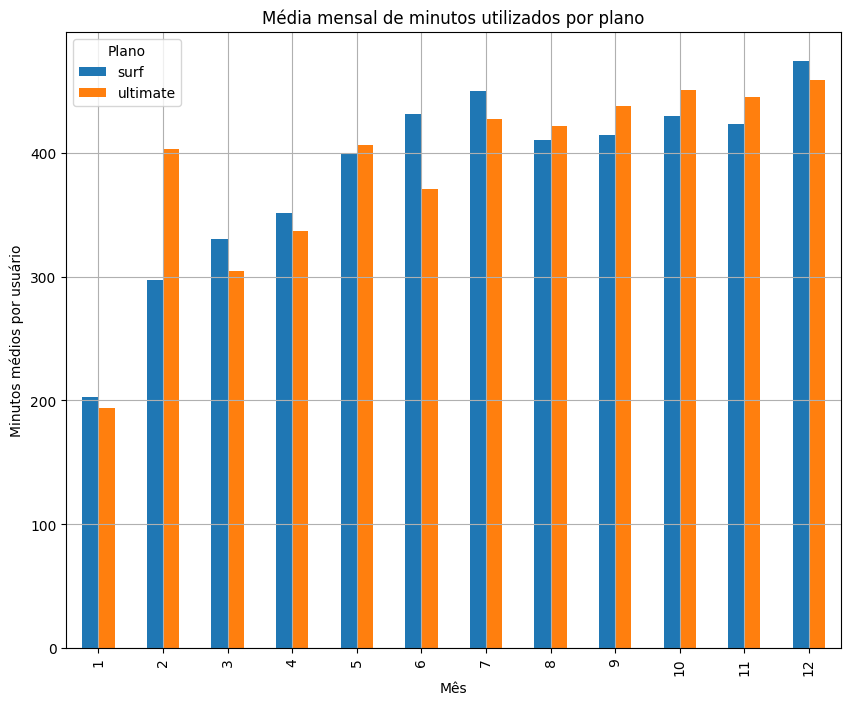

In [42]:
# Compare a duração média das chamadas de cada plano para cada mês. 
# Crie um gráfico de barras para visualizar o resultado.

# pivot_table para visualizar a soma
df_duracao_mes_chamadas = df_receita.pivot_table(
    index='month',      
    columns='plan', 
    values= 'minutes_used',
    aggfunc= 'mean'
)

#plotando gráfico
df_duracao_mes_chamadas.plot(kind = 'bar', title = "Média mensal de minutos utilizados por plano", xlabel = 'Mês', ylabel = 'Minutos médios por usuário', figsize = (10,8), grid = True)
plt.legend(title='Plano')
plt.show()

#optei por fazer com pivot_table porque pareceu mais fácil de plotar o gráfico

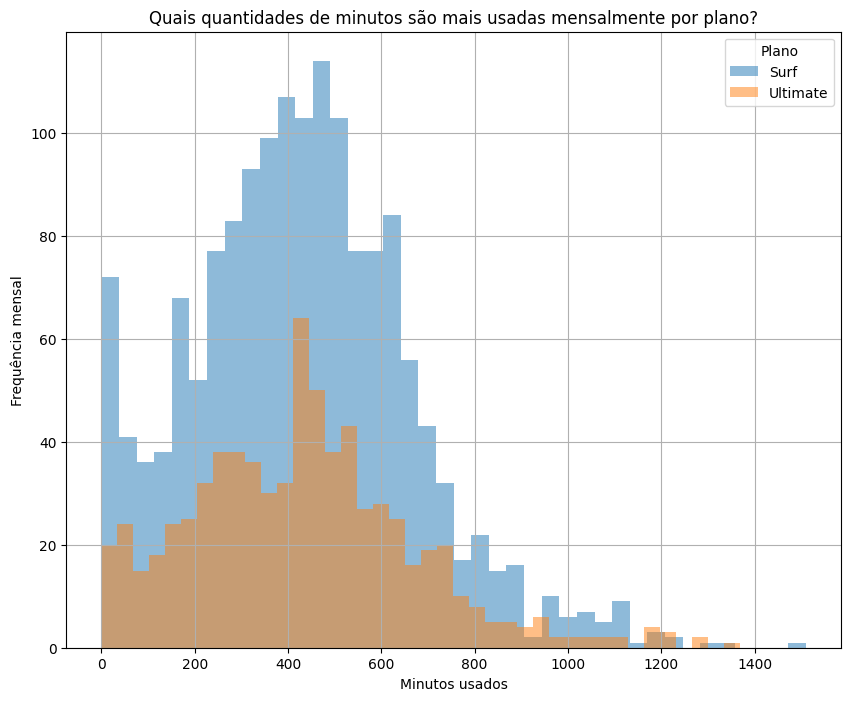

In [43]:
# Compare o número de minutos que os usuários de cada plano necessitam a cada mês. Construa um histograma.

#Filtrando os gráficos e atribuindo a variáveis
surf_minutos_hist = df_receita[df_receita['plan'] == 'surf']['minutes_used']
ultimate_minutos_hist = df_receita[df_receita['plan'] == 'ultimate']['minutes_used']

# Plotando histogramas
surf_minutos_hist.plot(kind = 'hist', bins = 40, title = "Quais quantidades de minutos são mais usadas mensalmente por plano?", xlabel = 'Minutos usados', ylabel = 'Usuários', figsize = (10,8), grid = True, alpha = 0.5, label = 'Surf')
ultimate_minutos_hist.plot(kind = 'hist',bins = 40, title = "Quais quantidades de minutos são mais usadas mensalmente por plano?", figsize = (10,8), grid = True, alpha = 0.5, label = 'Ultimate')
#Configurando com plt. o que não pude configurar no plot
plt.xlabel('Minutos usados')
plt.ylabel('Frequência mensal')
plt.legend(title='Plano')
plt.show()

In [44]:

# Calcule a média e a variância da duração mensal das chamadas

# Calculando valores para plano Surf
display(surf_minutos_hist.mean())
display(surf_minutos_hist.var())

# Calculando valores para plano Ultimate
display(ultimate_minutos_hist.mean())
display(ultimate_minutos_hist.var())

#Valores próximos

428.7495232040687

54968.279460650374

430.45

57844.46481223922

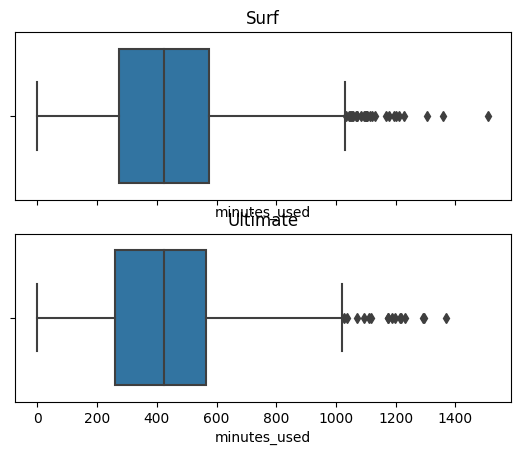

In [45]:
# Faça um diagrama de caixa para visualizar a distribuição da duração mensal das chamadas

fig, axes = plt.subplots(2, 1, sharex = True)
sns.boxplot(surf_minutos_hist, ax = axes[0])
sns.boxplot(ultimate_minutos_hist, ax = axes[1])
axes[0].set_title('Surf')
axes[1].set_title('Ultimate')
plt.show()

**Conclusões preliminares**

Os dados mostram que:
1) Há uma subutilização do plano Ultimate.
2) Há sobreutilização do plano Surf.
3) Os comportamentos de uso são semelhantes no que diz respeito ao maior volume de dados, diferindo nos outliers (valores que fogem do normal, todos superiores a Q4 no caso em análise).


O que, nos gráficos, sinaliza para as afirmações acima é:
1) O plano Ultimate oferece 3000 minutos mensais de franquia para chamadas, mas até mesmo o valor máximo dos outliers não passa de 1400 minutos usados.
2) A mediana do plano Surf está situada pouco acima de 400 minutos mensais. O limite de Q3 está situado pouco antes de 600. Considerando que IQR concentra 50% do volume dos dados e uma parte significativa de Q3 está após a marca de 500 minutos mensais usados (total da franquia Surf), há muitos usuários estourando o valor máximo da franquia, gerando valores extras para a empresa.
3) Tamanho dos IQRs praticamente iguais. Tamanho dos bigodes muito semelhantes, com bigode superior de Ultimate um pouco maior, o que não impacta na análise de negócio dada a alta franquia. Porém, há uma concentração de outliers aparentemente maior em Surf, o que, além de ratificar a afirmação 2, é significativo em termos de receita do plano específico.

Entendo que Surf está sendo mais lucrativo para a empresa do que Ultimate devido, em especial, aos valores de parte do terceiro quartil até os outliers. Talvez bem mais lucrativo, necessário analisar. Entendo também que a franquia de minutos de Ultimate está muito subutilizada.

### Mensagens

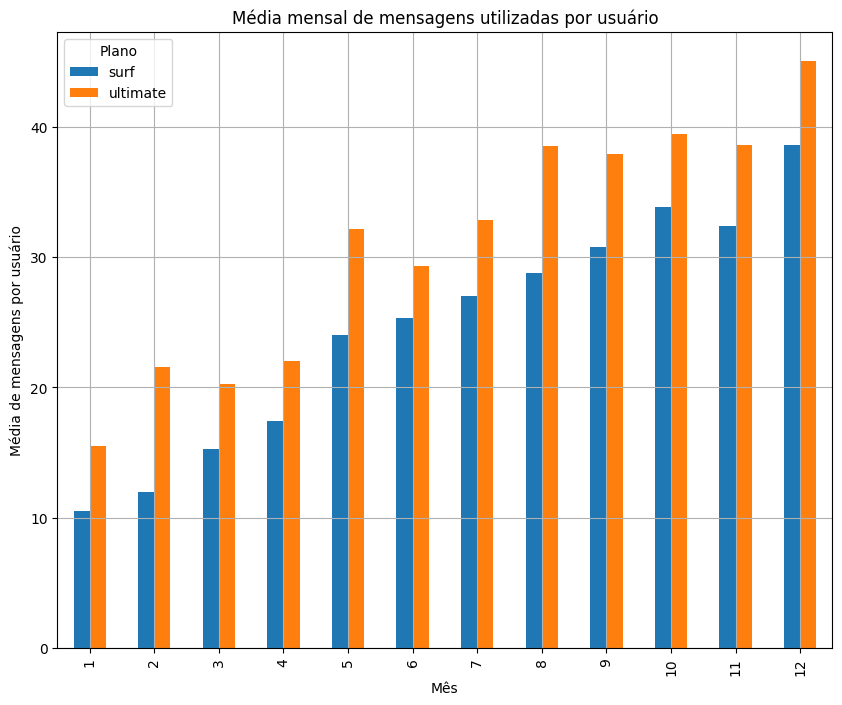

In [46]:
# Compare o número de mensagens que os usuários de cada plano costumam enviar a cada mês

#Comparando médias de mensagens por usuário, por mês, por plano
# pivot_table para visualizar a soma
df_media_msgs_plano = df_receita.pivot_table(
    index='month',      
    columns='plan', 
    values= 'messages_number',
    aggfunc= 'mean'
)

#plotando gráfico
df_media_msgs_plano.plot(kind = 'bar', title = "Média mensal de mensagens utilizadas por usuário", xlabel = 'Mês', ylabel = 'Média de mensagens por usuário', figsize = (10,8), grid = True)
plt.legend(title='Plano')
plt.show()



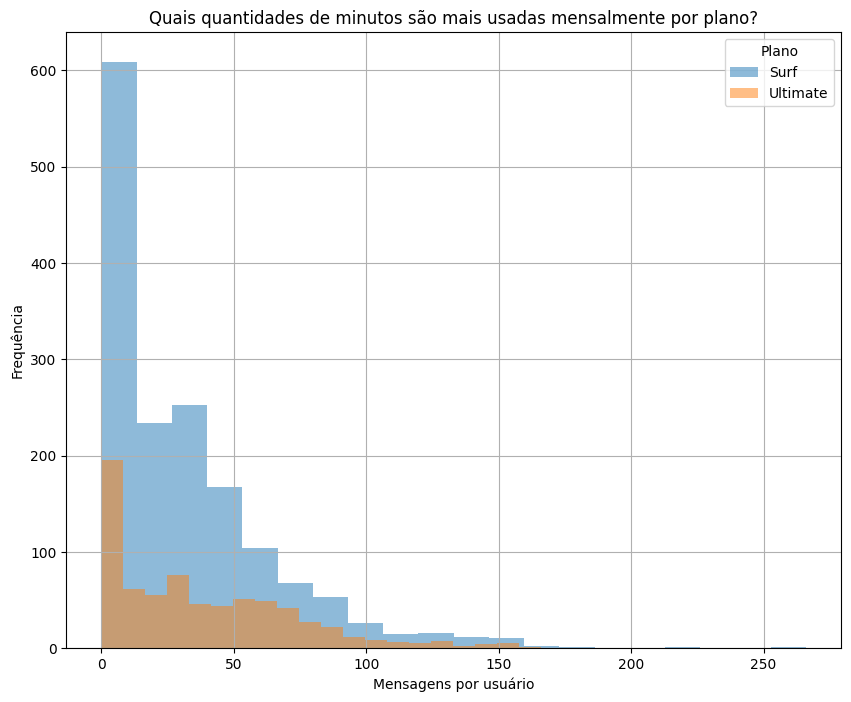

In [47]:
#Filtrando os gráficos e atribuindo a variáveis
surf_msgs_hist = df_receita[df_receita['plan'] == 'surf']['messages_number']
ultimate_msgs_hist = df_receita[df_receita['plan'] == 'ultimate']['messages_number']

# Plotando histogramas
surf_msgs_hist.plot(kind = 'hist', bins = 20, title = "Quais quantidades de mensagens são mais usadas mensalmente por plano?", figsize = (10,8), grid = True, alpha = 0.5, label = 'Surf')
ultimate_msgs_hist.plot(kind = 'hist',bins = 20, title = "Quais quantidades de minutos são mais usadas mensalmente por plano?", figsize = (10,8), grid = True, alpha = 0.5, label = 'Ultimate')
#Configurando com plt. o que não pude configurar no plot
plt.xlabel('Mensagens por usuário')
plt.ylabel('Frequência')
plt.legend(title='Plano')
plt.show()

In [48]:
#verificando se zero é realmente o valor com mais aparições nos planos

#verificando percentual de aparições do maior valor no plano surf
maiorvalor_surf = (surf_msgs_hist.value_counts()).index[0]
n_aparicoes_maiorvalor_surf = surf_msgs_hist.value_counts().loc[0]
n_total_valores_paramsgs_enviadas = len(df_receita['messages_number'])
percent_aparicoes_maiorvalor_surf = n_aparicoes_maiorvalor_surf / n_total_valores_paramsgs_enviadas
display(percent_aparicoes_maiorvalor_surf)

#verificando percentual de aparições do maior valor no plano ultimate
maiorvalor_ultimate = (ultimate_msgs_hist.value_counts()).index[0]
display(maiorvalor_ultimate)
n_aparicoes_maiorvalor_ultimate = ultimate_msgs_hist.value_counts().loc[0]
n_total_valores_paramsgs_enviadas = len(df_receita['messages_number'])
percent_aparicoes_maiorvalor_ultimate = n_aparicoes_maiorvalor_ultimate / n_total_valores_paramsgs_enviadas
display(percent_aparicoes_maiorvalor_ultimate)


0.1530745747928478

0.0

0.05931094635848234

In [49]:
# Calcule a média e a variância da duração mensal das chamadas

# Calculando valores para plano Surf
display(surf_msgs_hist.mean())
display(surf_msgs_hist.var())

# Calculando valores para plano Ultimate
display(ultimate_msgs_hist.mean())
display(ultimate_msgs_hist.var())

31.15956770502225

1126.7245219504066

37.55138888888889

1208.7567435481378

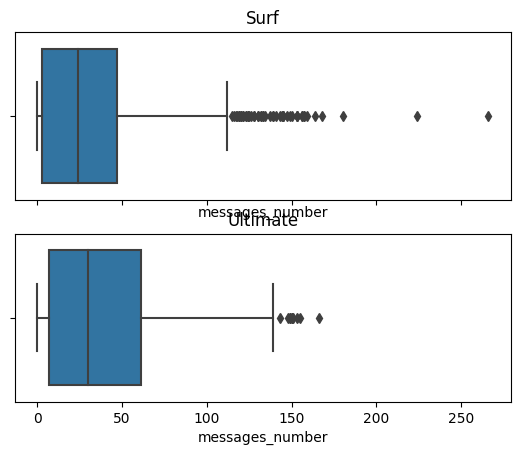

In [50]:
# Faça um diagrama de caixa para visualizar a distribuição da duração mensal das chamadas

fig, axes = plt.subplots(2, 1, sharex = True)
sns.boxplot(surf_msgs_hist, ax = axes[0])
sns.boxplot(ultimate_msgs_hist, ax = axes[1])
axes[0].set_title('Surf')
axes[1].set_title('Ultimate')
plt.show()

### Conclusões

1) Novamente, subutilização das franquias - dessa vez, de ambos os planos.
2) Há um maior espalhamento de valores no plano Ultimate do que em Surf, com enviesamento dos dados à direita em ambos planos.
3) Há mais outliers em Surf que em Ultimate


O que, nos gráficos, sinaliza para as afirmações acima é:

1) Em ambos os planos, os valores máximos dos conjuntos ficam muito longe das franquias disponibilizadas, mesmo considerando-se os outliers.
2) O IQR, o boxplot e a mediana de Ultimate  são superiores aos de Surf. Isso é compreensível, porque usuários do plano têm maior franquia. Mas os dados estão enviesados à direita em ambos os planos.
3) Conforme pode ser visualizado no boxplot.

Dos dados, a conclusão geral que tomo é que existe subutilização das franquias, pois mesmo considerando-se os outliers de cada plano, nenhum se aproxima das franquias contratadas. 
De forma acessória, parece haver uma  tendência, já observada no gráfico anterior, de que usuários do plano Surf, mais barato e com menos franquia, mais comumente extrapolem o plano contratado, pois há mais valores outliers em SUrf que em Ultimate.


### Internet

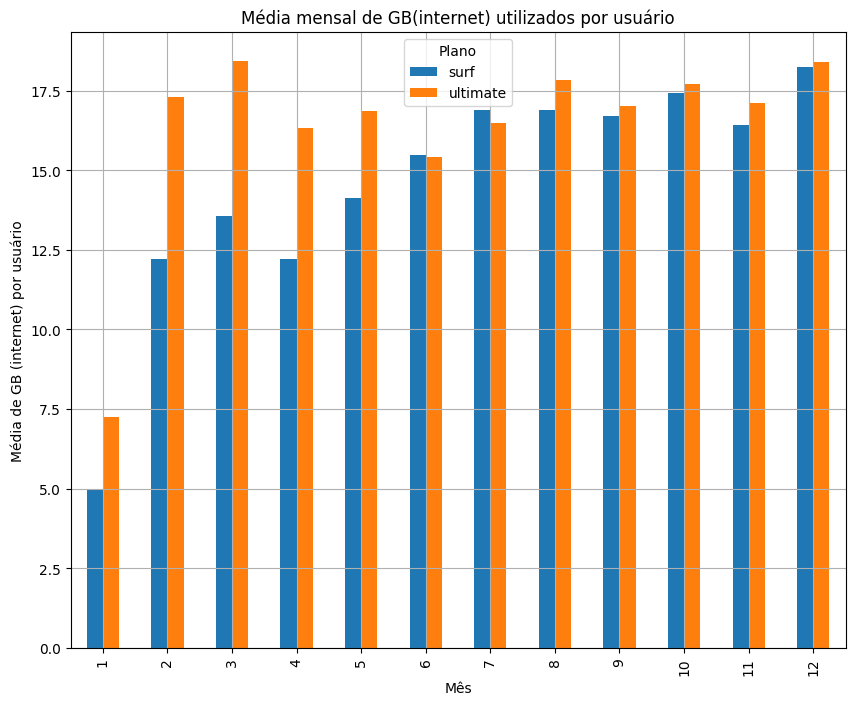

In [51]:
# Compare a quantidade de tráfego de internet consumido pelos usuários por plano
#Comparando médias de consumo de internet por usuário, por mês, por plano

# pivot_table para visualizar a soma
df_media_internet_plano = df_receita.pivot_table(
    index='month',      
    columns='plan', 
    values= 'gb_used',
    aggfunc= 'mean'
)

#plotando gráfico
df_media_internet_plano.plot(kind = 'bar', title = "Média mensal de GB(internet) utilizados por usuário", xlabel = 'Mês', ylabel = 'Média de GB (internet) por usuário', figsize = (10,8), grid = True)
plt.legend(title='Plano')
plt.show()

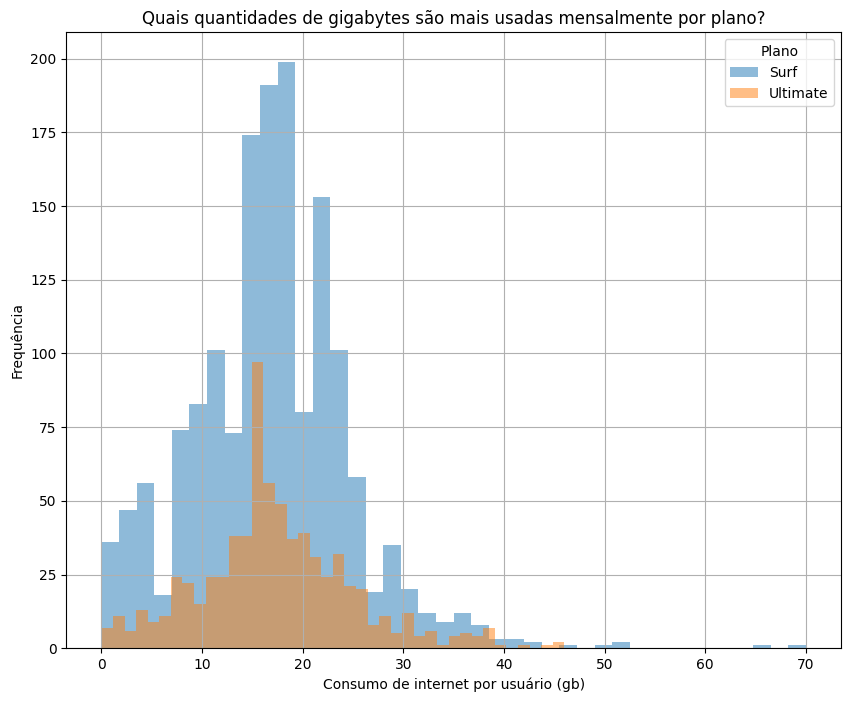

In [52]:
#Filtrando os gráficos e atribuindo a variáveis
surf_internet_hist = df_receita[df_receita['plan'] == 'surf']['gb_used']
ultimate_internet_hist = df_receita[df_receita['plan'] == 'ultimate']['gb_used']

# Plotando histogramas
surf_internet_hist.plot(kind = 'hist', bins = 40, title = "Quais quantidades de gigabytes são mais usadas mensalmente por plano?", figsize = (10,8), grid = True, alpha = 0.5, label = 'Surf')
ultimate_internet_hist.plot(kind = 'hist',bins = 40, title = "Quais quantidades de gigabytes são mais usadas mensalmente por plano?", figsize = (10,8), grid = True, alpha = 0.5, label = 'Ultimate')

#Configurando com plt. o que não pude configurar no plot
plt.xlabel('Consumo de internet por usuário (gb)')
plt.ylabel('Frequência')
plt.legend(title='Plano')
plt.show()

In [53]:
# Calcule a média e a variância da duração mensal das chamadas
#Acrescento valor da mediana de cada

# Calculando valores para plano Surf
display(surf_internet_hist.mean())
display(surf_internet_hist.median())
display(surf_internet_hist.var())

# Calculando valores para plano Ultimate
display(ultimate_internet_hist.mean())
display(ultimate_internet_hist.median())
display(ultimate_internet_hist.var())

16.670692943420217

17.0

61.58359983759012

17.306944444444444

17.0

58.830549760469786

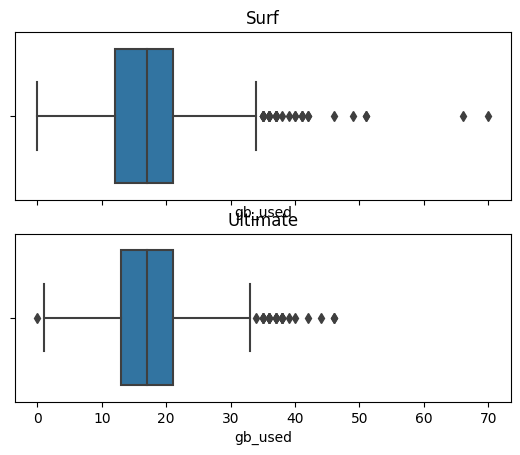

In [54]:
# Faça um diagrama de caixa para visualizar a distribuição da duração mensal das chamadas

fig, axes = plt.subplots(2, 1, sharex = True)
sns.boxplot(surf_internet_hist, ax = axes[0])
sns.boxplot(ultimate_internet_hist, ax = axes[1])
axes[0].set_title('Surf')
axes[1].set_title('Ultimate')
plt.show()

**Conclusões preliminares**

1) Ambos planos extrapolam limites das franquias (no caso de Surf, significativamente).
2) Numericamente, o comportamento é muito semelhante.
3) Ao se considerar as franquias, porém, o comportamento numericamente semelhante é muito relevante para fins de receita.

Porque:
1) Até mesmo a média e a mediana do plano Surf são superiores à franquia do plano, o que significa que mais de 50% dos usuários do plano estouram a franquia contratada. No caso de Ultimate, o box plot indica que há uma pequena parte dos valores consumidos acima de 30gb, constante do último quartil, além de outliers.
2) Médias, medianas, variâncias e IQR de ambos os conjuntos são muito próximas. Visualmente, os boxplots ainda indicam limites máximos e mínimos de consumo muito próximos. Os outliers são semelhantes também, com destaque para poucos outliers muito fora da curva em Surf.
3) Porém, esse comportamento numericamente semelhante causa impactos significativos na receita. Além de 50% dos usuários do plano Surf estourarem a franquia contratada, alguns chegam a consumir quase 70GB por mês (outliers), pagando excessos significativos. No caso de Ultimate, a franquia contratada é de 30GB e o valor por GB exc pago por Ultimate é menor que em Surf (7USD x 10USD). Assim, em termos de receita, o impacto dos extrapolamentos de Ultimate não é tão significativo.

Minha hipótese é de que o plano Surf é mais lucrativo para a empresa devido ao constante extrapolamento de limites de seus usuários. É necessário verificar em termos de receita.


## Receita

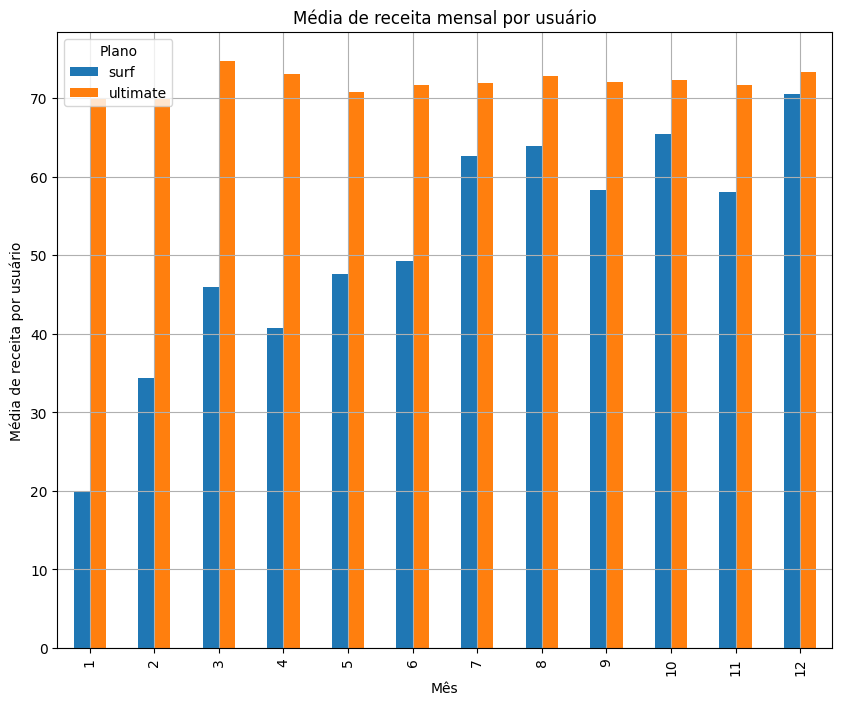

In [55]:
#Comparando médias de receita por usuário, por mês, por plano

# pivot_table para visualizar a soma
df_media_receita_plano = df_receita.pivot_table(
    index='month',      
    columns='plan', 
    values= 'month_value',
    aggfunc= 'mean'
)

#plotando gráfico
df_media_receita_plano.plot(kind = 'bar', title = "Média de receita mensal por usuário", xlabel = 'Mês', ylabel = 'Média de receita por usuário', figsize = (10,8), grid = True)
plt.legend(title='Plano')
plt.show()

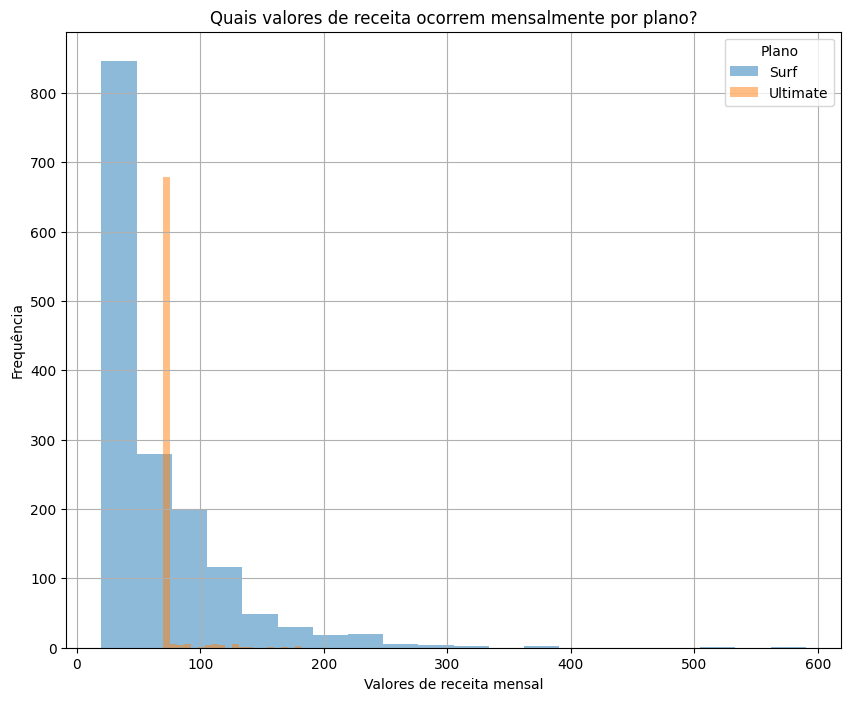

In [56]:
#Filtrando os gráficos e atribuindo a variáveis
surf_receita_hist = df_receita[df_receita['plan'] == 'surf']['month_value']
ultimate_receita_hist = df_receita[df_receita['plan'] == 'ultimate']['month_value']

# Plotando histogramas
surf_receita_hist.plot(kind = 'hist', bins = 20, title = "Quais valores de receita ocorrem mensalmente por plano?", figsize = (10,8), grid = True, alpha = 0.5, label = 'Surf')
ultimate_receita_hist.plot(kind = 'hist',bins = 20, title = "Quais valores de receita ocorrem mensalmente por plano?", figsize = (10,8), grid = True, alpha = 0.5, label = 'Ultimate')

#Configurando com plt. o que não pude configurar no plot
plt.xlabel('Valores de receita mensal')
plt.ylabel('Frequência')
plt.legend(title='Plano')
plt.show()

In [57]:
# Média, mediana e variância da receita mensal

# Calculando valores para plano Surf
display(surf_receita_hist.mean())
display(surf_receita_hist.median())
display(surf_receita_hist.var())
print()
# Calculando valores para plano Ultimate
display(ultimate_receita_hist.mean())
display(ultimate_receita_hist.median())
display(ultimate_receita_hist.var())

60.70640813731723

40.36

3067.835152293878

72.31388888888888

70.0

129.8484855509195

In [58]:
# Calculando a receita total anual

## plano Surf
display(surf_receita_hist.sum()) 
## plano Ultimate
display(ultimate_receita_hist.sum())

95491.18000000001

52066.0

In [59]:
#Calculando n de usuarios por plano
surf_nusuarios = df_receita[df_receita['plan'] == 'surf']['user_id'].nunique()
display(surf_nusuarios)
ultimate_nusuarios = df_receita[df_receita['plan'] == 'ultimate']['user_id'].nunique()
display(ultimate_nusuarios)

333

157

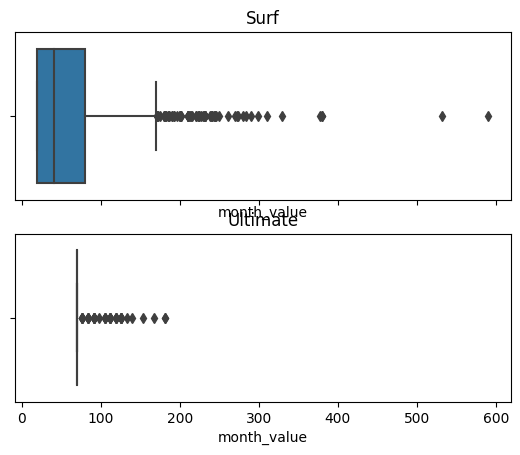

In [60]:
# Faça um diagrama de caixa para visualizar a distribuição da receita mensal das chamadas

fig, axes = plt.subplots(2, 1, sharex = True)
sns.boxplot(surf_receita_hist, ax = axes[0])
sns.boxplot(ultimate_receita_hist, ax = axes[1])
axes[0].set_title('Surf')
axes[1].set_title('Ultimate')
plt.show()

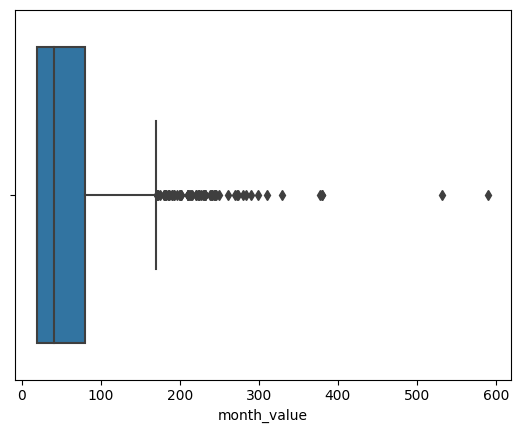

In [61]:
#Abrindo boxplot de Surf para melhor visualização

sns.boxplot(surf_receita_hist)
plt.show()

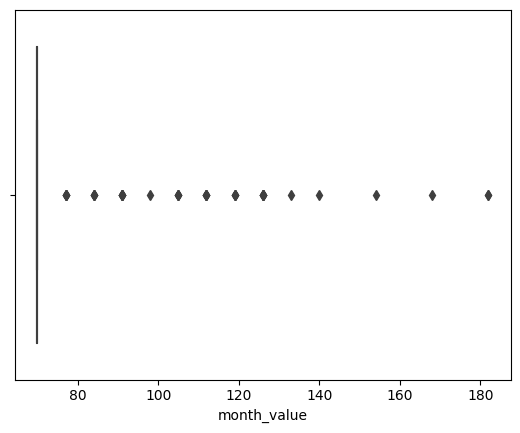

In [62]:
#Abrindo boxplot de Ultimate para melhor visualização

sns.boxplot(ultimate_receita_hist)
plt.show()

**Conclusões preliminares**

Os valores de média e receita total são os mais importantes para diagnóstico de receita. Deles, pode-se concluir que:
1) O plano Surf rendeu mais para a empresa no ano.
2) O plano Ultimate tem uma média mensal de receita por usuário maior que o plano Surf.
3) São raros os usuários de Ultimate que extrapolam os limites de franquia.
4) Por outro lado, é comum o extrapolamento da franquia por parte de usuário de Surf.

Porque:

1) Surf rendeu 95491 no ano, enquanto Ultimate rendeu 52066.
2) Média de surf é 60.7, média de Ultimate é 72.3. Isso ocorre embora a receita mensal seja maior em Surf que em Ultimate devido ao número de usuários em cada plano (para a amostra): 333 em Surf, 157 em Ultimate.
3) O boxplot de Ultimate mostra concentração do volume de dados centralizada em um valor, provavelmente em 70 USD, com alguns outliers.
4) A média de Surf é o valor mais importante para esse diagnóstico: 60.7, mais que o triplo do valor pago pela franquia original. Além disso, como sabemos que a mediana de Surf é de 40.36USD, podemos olhar para o boxplot de Surf e perceber a concentração do volume de dados enviesada para a direita desse valor (já superior à franquia), com muitos outliers, alguns muito maiores que o valor máximo do bigode do conjunto de dados.

Parece haver dois caminhos a seguir para maximizar receitas:
1) Trabalhar aumento nos valores mensais de Surf, sem desestímulo para que usuários deixem o plano.
2) Aumentar a atração de NOVOS usuários para Ultimate, dado que a média mensal de receita desse usuário é superior a Surf.

## Testes de hipótese


In [63]:
# Teste de diferença de receita média entre os planos Surf e Ultimate

#criando variáveis

##surf
df_media_receita_plano_surf = df_receita[df_receita['plan'] == 'surf']['month_value']


##ultimate
df_media_receita_plano_ultimate = df_receita[df_receita['plan'] == 'ultimate']['month_value']


#H₀: as médias das duas populações são iguais.
#H₁: as médias são diferentes.

#teste da hipótese nula
alpha = 0.05

results = st.ttest_ind(df_media_receita_plano_surf, df_media_receita_plano_ultimate, equal_var=False)

print(results.pvalue)

if results.pvalue < alpha:
	print("Rejeitamos a hipótese nula")
else:
	print("Não podemos rejeitar a hipótese nula")


3.1703905481137102e-15
Rejeitamos a hipótese nula


In [64]:
# Teste unilateral complementar: verificar se a receita média de Ultimate é maior que a de Surf

#H₀: a média de receita  da população de Ultimate é menor ou igual a de Surf
#H₁: a média de receita da população de Ultimate é maior que a de Surf

#teste da hipótese nula
alpha = 0.05

results = st.ttest_ind(df_media_receita_plano_surf, df_media_receita_plano_ultimate, equal_var=False)

print(results.pvalue / 2)

if results.pvalue / 2 < alpha and (df_media_receita_plano_ultimate.mean() > df_media_receita_plano_surf.mean()):
	print("Rejeitamos a hipótese nula")
else:
	print("Não podemos rejeitar a hipótese nula")


1.5851952740568551e-15
Rejeitamos a hipótese nula


In [65]:
# Teste de diferença de receita média entre NY-NJ e demais regiões
## H0 = receita média dos usuários da área de NY-NJ é semelhante a de demais áreas
## H1 = receita média dos usuários da área de NY-NJ difere de demais áreas


In [66]:
#criando variáveis 

## variável NY-NJ
df_nynj1 = df_receita[df_receita['city'].str.contains('NY-NJ', na=False)]['month_value']

## variável demais cidades
df_another_cities = df_receita[df_receita['city'] != 'New York-Newark-Jersey City, NY-NJ-PA MSA']['month_value']

In [67]:
#teste de hipóteses

alpha = 0.05

results = st.ttest_ind(df_nynj1, df_another_cities, equal_var = False)

pvalue = results.pvalue
print('p-value:', pvalue)
if pvalue < alpha:
    print('Rejeitamos a hipótese nula')
else:
    print('Não é possível rejeitar a hipótese nula')


p-value: 0.03352561588530083
Rejeitamos a hipótese nula


In [68]:
# Como consequência, vamos verificar se a receita de NY é estatisticamente menor que as de demais áreas

#Verificando as médias das amostras
display(df_nynj1.mean())
display(df_another_cities.mean())

# fazendo teste unilateral para verificar se estatisticamente a média de NY é menor que a de demais cidades
#H₀: a média de receita da população de NY-NJ é maior ou igual as demais
#H₁: a média de receita da população de NY-NJ é menor que as demais

#teste da hipótese nula
alpha = 0.05

results = st.ttest_ind(df_nynj1, df_another_cities, equal_var=False)

print(results.pvalue / 2)

if results.pvalue / 2 < alpha and (df_nynj1.mean() < df_another_cities.mean()):
	print("Rejeitamos a hipótese nula")
else:
	print("Não podemos rejeitar a hipótese nula")

59.92135278514589

65.22277139874738

0.016762807942650414
Rejeitamos a hipótese nula


## Conclusão geral

Inicialmente, carreguei os cinco conjuntos de dados da amostra em questão. Visualizei cada um dos conjuntos para ter uma ideia dos mesmos. Efetuei o pré-processamento dos dados, na busca de valores ausentes e/ou duplicados, além de outras anomalias. Também visei a preparar os dados com maior qualidade, o que resultou em acrescentar uma coluna “month” baseada na data (que depois criei em demais dfs), renomear colunas e na modificação de tipos de dados, especialmente colunas que registravam datas e constavam como “object”: essas foram alteradas para datetime.

A seguir, realizei agrupamentos para calcular números de chamadas, minutos e internet por mês, por usuário. Criei novo df agrupando todos esses dados. Arredondei os valores necessários para cima. Calculei receita mensal por usuário. Criei novas colunas com os excedentes.

Na análise do comportamento dos usuários, o uso mensal de chamadas se mostrou relativamente semelhante entre os planos Surf e Ultimate, embora com variação considerável entre usuários. No caso das mensagens, usuários do plano Ultimate tendem a enviar mais mensagens, mas os dois planos apresentam muitos usuários com baixo ou nenhum envio mensal. Já no consumo de internet, os dois planos apresentam uso relevante, mas o plano Surf tem maior tendência a ultrapassar o limite incluído, o que contribui para a cobrança de excedentes. Na análise de receita, o plano Surf gerou mais receita total na amostra, enquanto o plano Ultimate apresentou maior receita média mensal por usuário.

Por fim, realizei os testes estatísticos para descobrir qual dos planos é o mais rentável. Com base na análise descritiva e nos testes estatísticos, há dois caminhos comerciais plausíveis:

1) Trabalhar aumento nos valores mensais de Surf (**com cuidado para que usuários não deixem o plano pela mudança de valor**) pois este é o plano que, em termos absolutos, mais gerou receita para a empresa.
2) Aumentar a atração de **novos** usuários para Ultimate, dado que a média mensal de receita desse usuário é superior a Surf.

Ainda, foi solicitada a verificação sobre se a receita média dos usuários de NY-NJ seria diferente da dos demais. Estatisticamente, há evidências de que as receitas médias dos planos são diferentes. Foi realizado um teste unilateral extra para verificar se a receita seria estatisticamente menor, conforme a amostra de dados sugeria, o qual sugere a receita média de NY-NJ ser menor que a de demais cidades. Assim, sugere-se, por fim:

3) Investigar a menor receita média dos usuárioss de NY-NJ antes de definir ações comerciais específicas para essa região.


**Nota estatística:** o p-valor do teste NY-NJ × demais regiões é aproximadamente 0,034, próximo ao limiar de 0,05. O resultado é significativo ao nível adotado, mas deve ser interpretado com cautela e validado com novas amostras.
